<a href="https://colab.research.google.com/github/Abcd-7474/Personal-Projects/blob/main/PINN_PH1050.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

PINN solving the 1-D wave equation u_tt = c²u_xx on [0,1]×[0,1], with u(x,0)=sin(πx), u_t(x,0)=0 and fixed ends. Network: 4 hidden layers × 50 neurons, tanh. Compared against the exact solution sin(πx)cos(πct).

In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

In [2]:
class PINN(nn.Module):
    def __init__(self, layers):
        super(PINN, self).__init__()
        self.activation = nn.Tanh()
        layer_list = []
        for i in range(len(layers) - 1):
            layer_list.append(nn.Linear(layers[i], layers[i+1]))
        self.layers = nn.ModuleList(layer_list)

    def forward(self, x, t):
        inputs = torch.cat([x, t], dim=1)
        for layer in self.layers[:-1]:
            inputs = self.activation(layer(inputs))
        return self.layers[-1](inputs)

In [3]:
x_min, x_max = 0.0, 1.0
t_min, t_max = 0.0, 1.0
N_pde = 2000
N_ic = 100
N_bc = 100

# PDE collocation points
x_pde = torch.rand(N_pde, 1)
t_pde = torch.rand(N_pde, 1)

# Initial displacement: u(x,0) = sin(pi x)
x_ic1 = torch.rand(N_ic, 1)
t_ic1 = torch.zeros(N_ic, 1)
u_ic1 = torch.sin(np.pi * x_ic1)

# Initial velocity: u_t(x,0) = 0
x_ic2 = torch.rand(N_ic, 1)
t_ic2 = torch.zeros(N_ic, 1)
u_t_ic2 = torch.zeros(N_ic, 1)

# Fixed ends: u(0,t) = u(1,t) = 0
x_bc = torch.cat([torch.zeros(N_bc//2, 1), torch.ones(N_bc//2, 1)])
t_bc = torch.rand(N_bc, 1)
u_bc = torch.zeros(N_bc, 1)

In [4]:
def pde_residual(model, x, t, c=1.0):
    x = x.clone().detach().requires_grad_(True)
    t = t.clone().detach().requires_grad_(True)
    u = model(x, t)
    u_t = torch.autograd.grad(u, t, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_x = torch.autograd.grad(u, x, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_tt = torch.autograd.grad(u_t, t, grad_outputs=torch.ones_like(u_t), create_graph=True)[0]
    u_xx = torch.autograd.grad(u_x, x, grad_outputs=torch.ones_like(u_x), create_graph=True)[0]
    return u_tt - c**2 * u_xx

def compute_u_t(model, x, t):
    x = x.clone().detach().requires_grad_(True)
    t = t.clone().detach().requires_grad_(True)
    u = model(x, t)
    return torch.autograd.grad(u, t, grad_outputs=torch.ones_like(u), create_graph=True)[0]

def loss_function(model, x_pde, t_pde, x_ic1, t_ic1, u_ic1,
                  x_ic2, t_ic2, u_t_ic2, x_bc, t_bc, u_bc):
    loss_pde = torch.mean(pde_residual(model, x_pde, t_pde, c=1.0)**2)
    loss_ic1 = torch.mean((model(x_ic1, t_ic1) - u_ic1)**2)
    loss_ic2 = torch.mean((compute_u_t(model, x_ic2, t_ic2) - u_t_ic2)**2)
    loss_bc  = torch.mean((model(x_bc, t_bc) - u_bc)**2)
    total = loss_pde + loss_ic1 + loss_ic2 + loss_bc
    return total, loss_pde, loss_ic1, loss_ic2, loss_bc

In [5]:
layers = [2, 50, 50, 50, 50, 1]
model = PINN(layers)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

num_epochs = 5000
print("Training the PINN")
for epoch in range(num_epochs):
    optimizer.zero_grad()
    total_loss, loss_pde, loss_ic1, loss_ic2, loss_bc = loss_function(
        model, x_pde, t_pde, x_ic1, t_ic1, u_ic1, x_ic2, t_ic2, u_t_ic2, x_bc, t_bc, u_bc)
    total_loss.backward()
    optimizer.step()
    if epoch % 250 == 0:
        print(f'Epoch {epoch}/{num_epochs}, Loss: {total_loss.item():.6f}, '
              f'PDE: {loss_pde.item():.6f}, IC1: {loss_ic1.item():.6f}, '
              f'IC2: {loss_ic2.item():.6f}, BC: {loss_bc.item():.6f}')
print("Training done.")

Training the PINN
Epoch 0/5000, Loss: 0.510466, PDE: 0.000073, IC1: 0.509266, IC2: 0.000807, BC: 0.000320
Epoch 250/5000, Loss: 0.008521, PDE: 0.001089, IC1: 0.000624, IC2: 0.002632, BC: 0.004177
Epoch 500/5000, Loss: 0.002630, PDE: 0.000444, IC1: 0.000035, IC2: 0.001459, BC: 0.000692
Epoch 750/5000, Loss: 0.001145, PDE: 0.000228, IC1: 0.000048, IC2: 0.000748, BC: 0.000122
Epoch 1000/5000, Loss: 0.000623, PDE: 0.000150, IC1: 0.000065, IC2: 0.000361, BC: 0.000047
Epoch 1250/5000, Loss: 0.000482, PDE: 0.000135, IC1: 0.000055, IC2: 0.000234, BC: 0.000058
Epoch 1500/5000, Loss: 0.000383, PDE: 0.000125, IC1: 0.000056, IC2: 0.000145, BC: 0.000057
Epoch 1750/5000, Loss: 0.000334, PDE: 0.000115, IC1: 0.000048, IC2: 0.000112, BC: 0.000060
Epoch 2000/5000, Loss: 0.000286, PDE: 0.000106, IC1: 0.000044, IC2: 0.000082, BC: 0.000055
Epoch 2250/5000, Loss: 0.000252, PDE: 0.000098, IC1: 0.000040, IC2: 0.000060, BC: 0.000054
Epoch 2500/5000, Loss: 0.000251, PDE: 0.000094, IC1: 0.000046, IC2: 0.000055, 

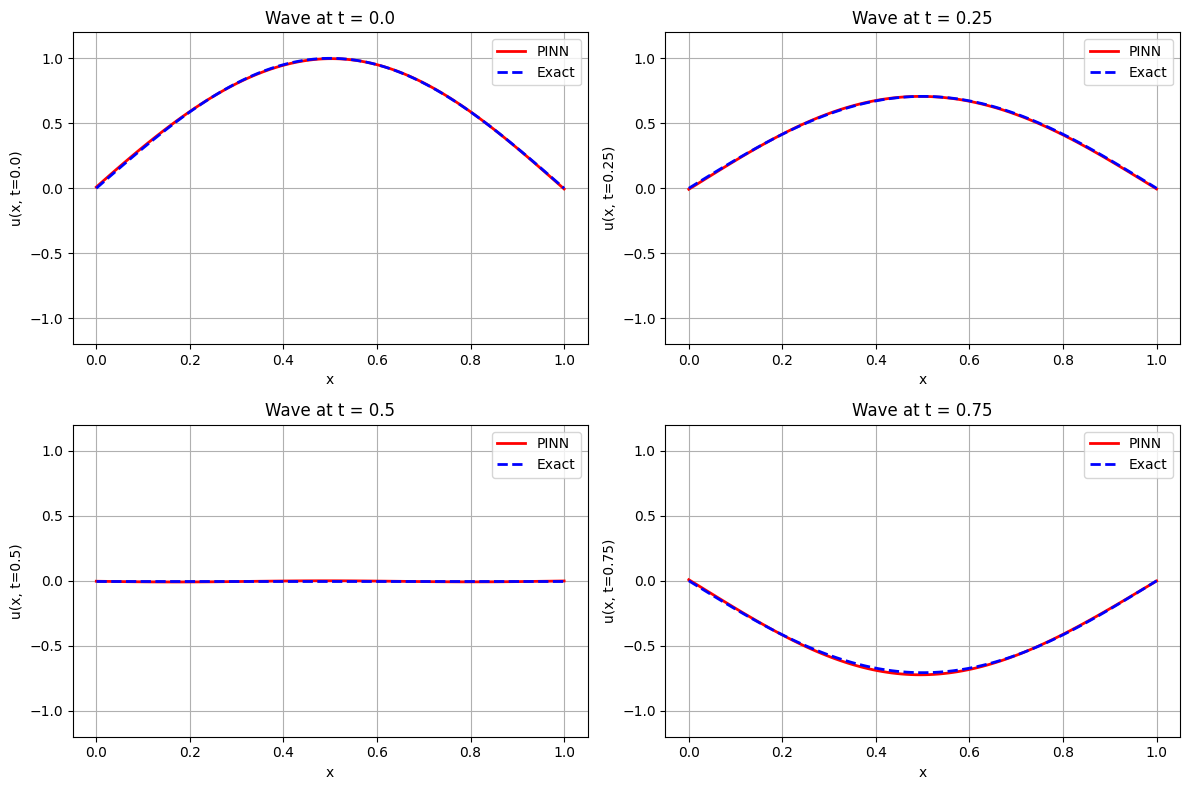

In [6]:
x_test = torch.linspace(0, 1, 100).reshape(-1, 1)
times = [0.0, 0.25, 0.5, 0.75]
c = 1.0

plt.figure(figsize=(12, 8))
for i, t_val in enumerate(times):
    t_plot = t_val * torch.ones_like(x_test)
    with torch.no_grad():
        u_pred = model(x_test, t_plot)
        u_exact = torch.sin(np.pi * x_test) * torch.cos(c * np.pi * t_plot)
    plt.subplot(2, 2, i+1)
    plt.plot(x_test.numpy(), u_pred.numpy(), 'r-', label='PINN', linewidth=2)
    plt.plot(x_test.numpy(), u_exact.numpy(), 'b--', label='Exact', linewidth=2)
    plt.xlabel('x'); plt.ylabel(f'u(x, t={t_val})')
    plt.title(f'Wave at t = {t_val}')
    plt.legend(); plt.grid(True); plt.ylim([-1.2, 1.2])
plt.tight_layout()
plt.show()